# GSE119526

> - Author: Cao Qiang
> - Email: qiangcao2014@gmail.com
> - Create: 2023-01-08
> - Modified: 2025-08-11

# 1. Experimental Design

> Genome-wide open chromatin methylome profiles in colorectal cancer
> - Homo sapiens
> - GPL21145: Illumina Infinium MethylationEPIC BeadChip
> - Sun Yat-sen University
> - Huichuan Yu, Xiaolin Wang, Liangliang Bai, Guannan Tang, Kelly T Carter, Ji Cui, Pinzhu Huang, Li Liang, Yanqing Ding, Muyan Cai, Meijin Huang, Huanliang Liu, Guangwen Cao, Steven Gallinger, Rish K Pai, Daniel D Buchanan, Aung Ko Win, Polly A Newcomb, Jianping Wang, William M Grady, Yanxin Luo, DNA methylation profile in CpG-depleted regions uncovers a high-risk subtype of early-stage colorectal cancer, JNCI: Journal of the National Cancer Institute, Volume 115, Issue 1, January 2023, Pages 52–61, https://doi.org/10.1093/jnci/djac183

| Sample | Tissue | Replicate |
| - | - | - |
| Normal | Colon adjacent normal | rep |
| Cancer | Colon cancer tissue | rep |

In [1]:
library(tidyverse)
suppressPackageStartupMessages(library(minfi))
suppressPackageStartupMessages(library(limma))
suppressPackageStartupMessages(library(DMRcate))
suppressPackageStartupMessages(library(IlluminaHumanMethylation450kmanifest))
suppressPackageStartupMessages(library(IlluminaHumanMethylation450kanno.ilmn12.hg19))
suppressPackageStartupMessages(library(RColorBrewer))

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.2     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


# 2. Download Data

In [2]:
suppressPackageStartupMessages(library(GEOquery))

In [3]:
gse_id <- "GSE119526"
data_dir <- file.path("~/dataset_1/methylation_dataset/array", gse_id)
dir.create(data_dir, showWarnings = FALSE)

In [4]:
getGEOSuppFiles(
    GEO = gse_id, makeDirectory = TRUE, 
    baseDir = "~/dataset_1/methylation_dataset/array")

,size,isdir,mode,mtime,ctime,atime,uid,gid,uname,grname,fname,destdir,filepath,GEO
,<dbl>,<lgl>,<octmode>,<dttm>,<dttm>,<dttm>,<int>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
~/dataset_1/methylation_dataset/array/GSE119526/GSE119526_Matrix_signal_intensities.csv.gz,439361539,FALSE,777,2026-04-12 11:30:58,2026-04-12 11:30:58,2026-04-12 11:30:58,1000,1000,fugui,fugui,GSE119526_Matrix_signal_intensities.csv.gz,~/dataset_1/methylation_dataset/array/GSE119526,~/dataset_1/methylation_dataset/array/GSE119526/GSE119526_Matrix_signal_intensities.csv.gz,GSE119526
~/dataset_1/methylation_dataset/array/GSE119526/GSE119526_RAW.tar,169021440,FALSE,777,2026-04-12 11:32:29,2026-04-12 11:32:29,2026-04-12 11:32:29,1000,1000,fugui,fugui,GSE119526_RAW.tar,~/dataset_1/methylation_dataset/array/GSE119526,~/dataset_1/methylation_dataset/array/GSE119526/GSE119526_RAW.tar,GSE119526


In [5]:
file.path(data_dir, paste0(gse_id, "_RAW.tar")) |>
    path.expand() |>
    untar(exdir = path.expand(file.path(data_dir, "idat")))

In [ ]:
list.files(file.path(data_dir, "idat"), pattern = "idat.gz$", full = TRUE) |>
    lapply(FUN = R.utils::gunzip, overwrite = TRUE) |>
    invisible()

In [7]:
mSet <- getGEO(
    GEO = gse_id, destdir = data_dir,
    AnnotGPL = TRUE, getGPL = FALSE)[[1]]
mSet

Found 1 file(s)

GSE119526_series_matrix.txt.gz



ERROR: [1m[33mError[39m in `httr2::req_perform()`:[22m
[33m![39m Failed to perform HTTP request.
[1mCaused by error in `curl::curl_fetch_memory()`:[22m
[33m![39m Timeout was reached [ftp.ncbi.nlm.nih.gov]:
Operation timed out after 120000 milliseconds with 232890607 out of 425727565 bytes received


In [ ]:
pData(mSet) |> select(
    Sample_Name = geo_accession, full_filenames = `supplementary_file.1`,
    Sample_Group = `tissue:ch1`, Sample_Gender = `gender:ch1`) |>
    mutate(
        full_filenames = basename(full_filenames),
        Sentrix_ID = str_extract(full_filenames, "\\d{10}"),
        Sentrix_Position = str_extract(full_filenames, "R\\d{2}C\\d{2}"),
        Basename = str_remove(full_filenames, "_Red\\.idat\\.gz$"),
        Sample_Group = case_when(
            str_detect(Sample_Group, "benign prostate tissues") ~ "Benign",
            str_detect(Sample_Group, "prostate cancer tumor") ~ "Cancer")) |>
    select(
        Sample_Name, Sample_Group, Sample_Gender, 
        Sentrix_ID, Sentrix_Position, Basename) |>
    write_csv(file.path(data_dir, "idat", "SampleSheet.csv"))

# 3. Loading Data

In [ ]:
sample_sheet <- file.path(data_dir, "idat") |>
    read.metharray.sheet(verbose = FALSE) |>
    mutate(
        Sample_Group = factor(
            Sample_Group, levels = c("Benign", "Cancer"))) |>
    arrange(Sample_Group) |> 
    group_by(Sample_Group) |> 
    mutate(Sample_Replicate = paste0("rep", row_number())) |>
    ungroup()

sample_sheet |> select(-Basename) |> head()

Sample_Name,Sample_Group,Sample_Gender,Array,Slide,Sample_Replicate
<chr>,<fct>,<chr>,<chr>,<chr>,<chr>
GSM1162363,Benign,male,R01C02,6264509108,rep1
GSM1162380,Benign,male,R03C02,6285609104,rep2
GSM1162381,Benign,male,R06C02,6285650040,rep3
GSM1162382,Benign,male,R01C01,6285650050,rep4
GSM1162364,Cancer,male,R04C02,6264509130,rep1
GSM1162365,Cancer,male,R03C02,6264509130,rep2


In [ ]:
rgSet <- read.metharray.exp(targets = sample_sheet)
# Set a descriptive name for the samples.
sampleNames(rgSet) <- paste0(
    rgSet$Sample_Group, "_", rgSet$Sample_Replicate)
rgSet

Warning message:
"Setting row names on a tibble is deprecated."


class: RGChannelSet 
dim: 622399 8 
metadata(0):
assays(2): Green Red
rownames(622399): 10600313 10600322 ... 74810490 74810492
rowData names(0):
colnames(8): Benign_rep1 Benign_rep2 ... Cancer_rep3 Cancer_rep4
colData names(8): Sample_Name Sample_Group ... Sample_Replicate
  filenames
Annotation
  array: IlluminaHumanMethylation450k
  annotation: ilmn12.hg19

# 4. Quality Control

## 1). Detection Probe

In [ ]:
# Detection p-values for all probed genomic positions.
detP <- detectionP(rgSet)
detP[1:6, 1:6]

,Benign_rep1,Benign_rep2,Benign_rep3,Benign_rep4,Cancer_rep1,Cancer_rep2
cg00050873,0.000000e+00,0,0.000000e+00,0.000000e+00,0.000000e+00,0
cg00212031,0.000000e+00,0,0.000000e+00,0.000000e+00,0.000000e+00,0
cg00213748,7.110664e-56,0,9.658263e-73,3.671506e-268,8.918628e-235,0
cg00214611,0.000000e+00,0,0.000000e+00,0.000000e+00,0.000000e+00,0
cg00455876,2.101831e-280,0,3.186284e-212,0.000000e+00,0.000000e+00,0
cg01707559,0.000000e+00,0,0.000000e+00,0.000000e+00,0.000000e+00,0


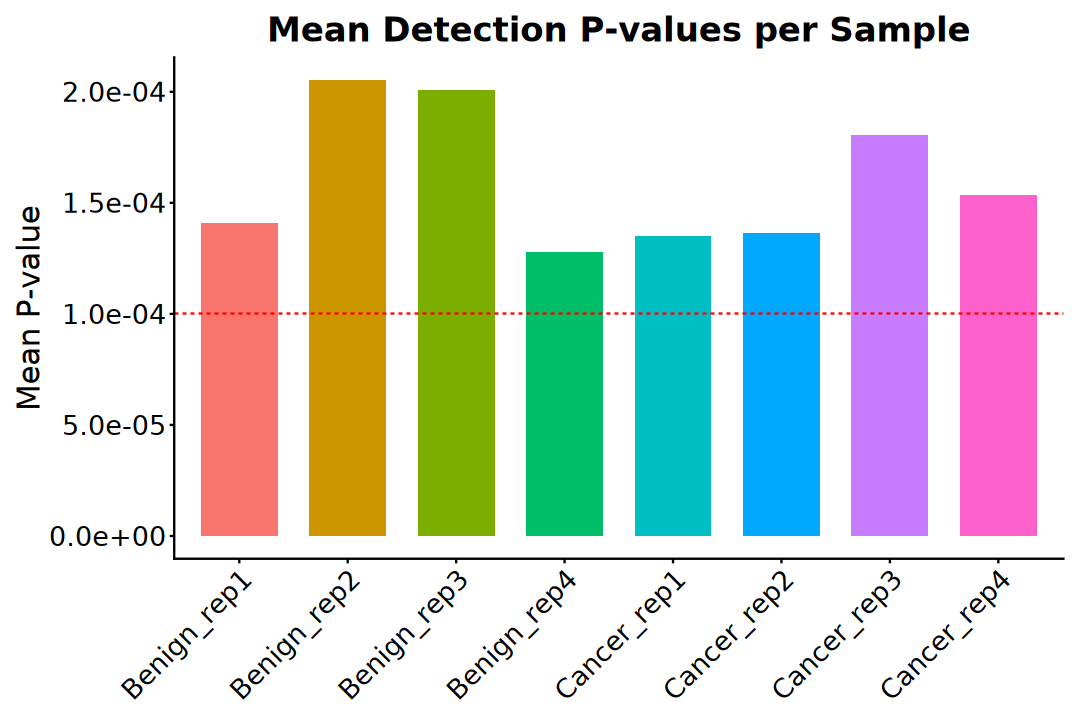

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

data.frame(
    Sample = colnames(detP), 
    MeanDetP = colMeans(detP)) |>
    arrange(MeanDetP) |>
    ggplot(aes(x = Sample, y = MeanDetP)) +
        geom_bar(aes(fill = Sample), stat = "identity", width = 0.7) +
        geom_hline(yintercept = 1e-04, linetype = "dashed", color = "red") +
        scale_y_continuous(labels = scales::label_scientific()) +
        labs(title = "Mean Detection P-values per Sample",
            x = NULL, y = "Mean P-value") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = margin(t = 10, r = 10, b = 10, l = 10),
            legend.position = "none",
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
            axis.text.y = element_text(size = 16),
            panel.grid.major = element_blank())

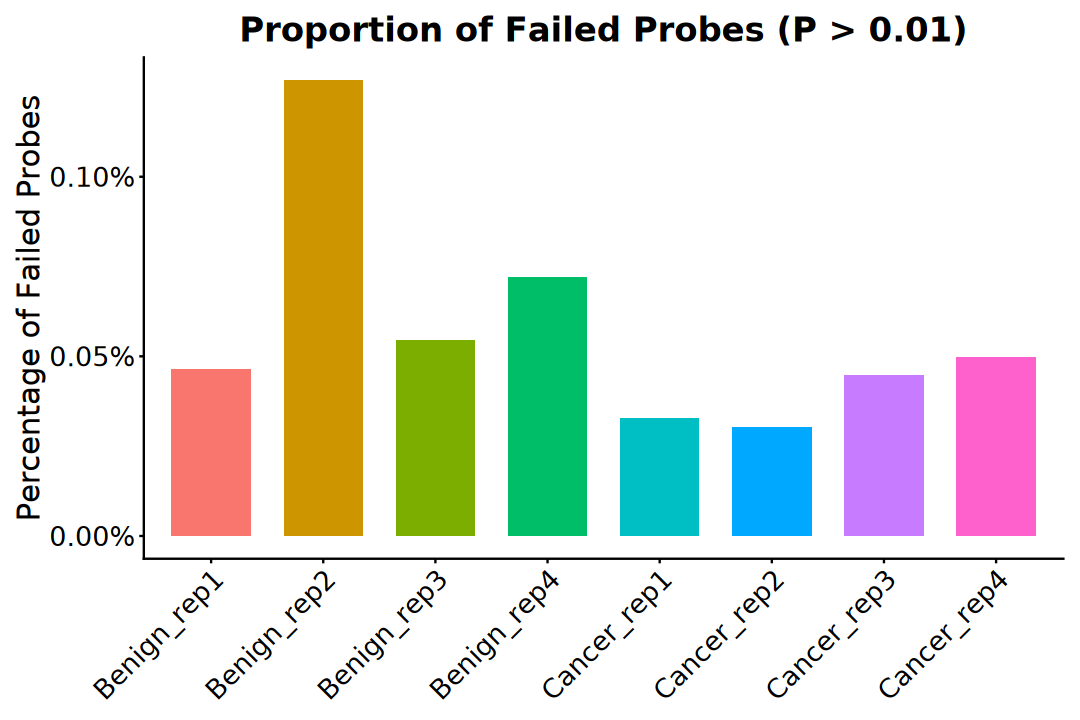

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

data.frame(
    Sample = colnames(detP), 
    FailureRate = colSums(detP > 0.01) / nrow(detP)) |>
    arrange(FailureRate) |>
    ggplot(aes(x = Sample, y = FailureRate)) +
        geom_bar(aes(fill = Sample), stat = "identity", width = 0.7) +
        scale_y_continuous(labels = scales::percent) +
        labs(title = "Proportion of Failed Probes (P > 0.01)",
            x = NULL, y = "Percentage of Failed Probes") +
        theme_classic() +
        theme(
            plot.title = element_text(size = 20, face = "bold", hjust = 0.5),
            plot.margin = margin(t = 10, r = 10, b = 10, l = 10),
            legend.position = "none",
            legend.title = element_text(size = 18),
            legend.text = element_text(size = 16),
            axis.title = element_text(size = 18),
            axis.text.x = element_text(size = 16, angle = 45, hjust = 1),
            axis.text.y = element_text(size = 16),
            panel.grid.major = element_blank())

## 2). minfi QC Report

In [ ]:
qcReport(
    rgSet = rgSet, sampNames = sampleNames(rgSet), 
    sampGroups = rgSet$Sample_Group,
    pdf = file.path(data_dir, "QCReport_minfi.pdf")) |>
    suppressWarnings()

agg_record_2d4e52e47720 
                      2

## 3). Visualization

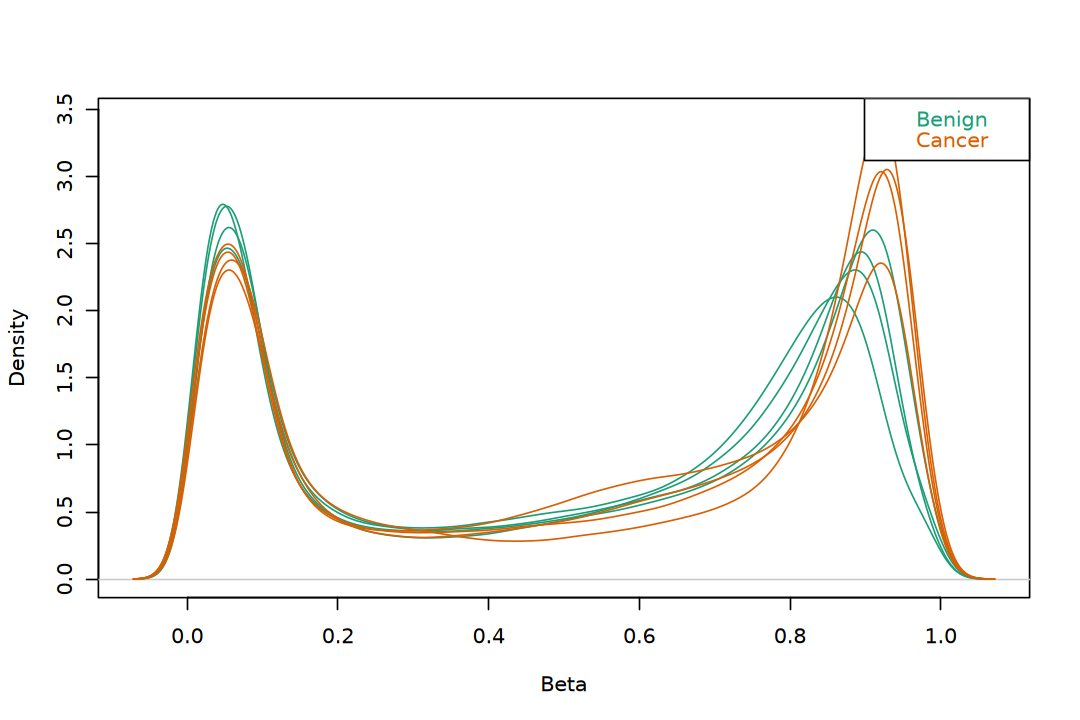

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

densityPlot(dat = rgSet, sampGroups = rgSet$Sample_Group)

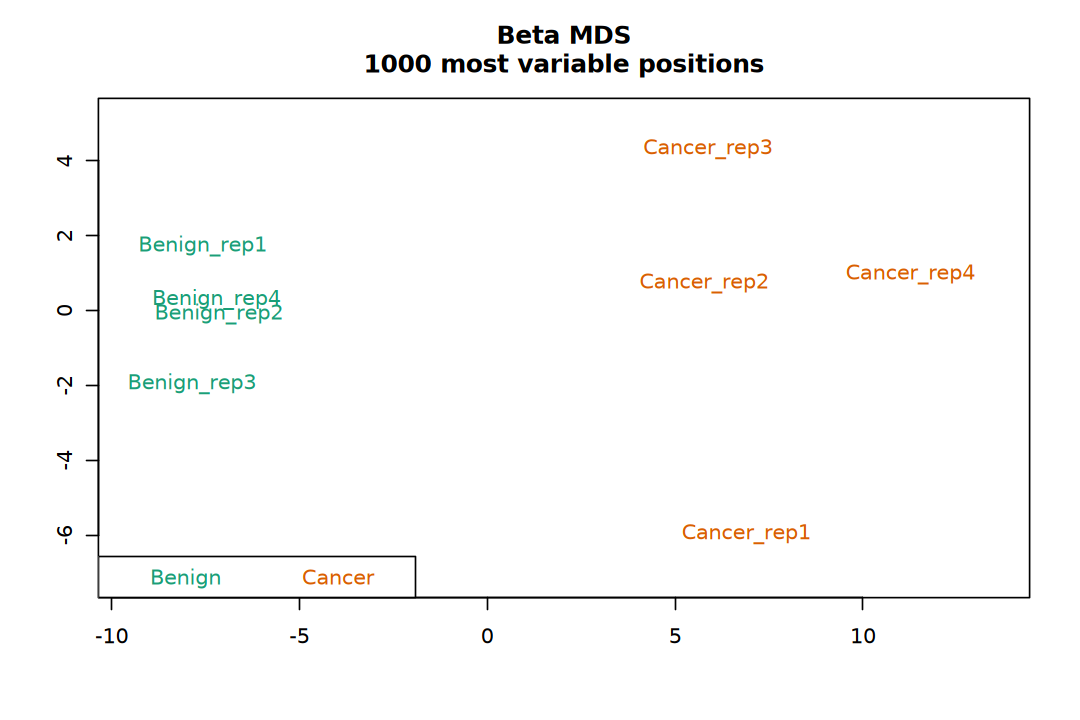

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

mdsPlot(
    dat = rgSet, sampNames = sampleNames(rgSet), 
    sampGroups = rgSet$Sample_Group)

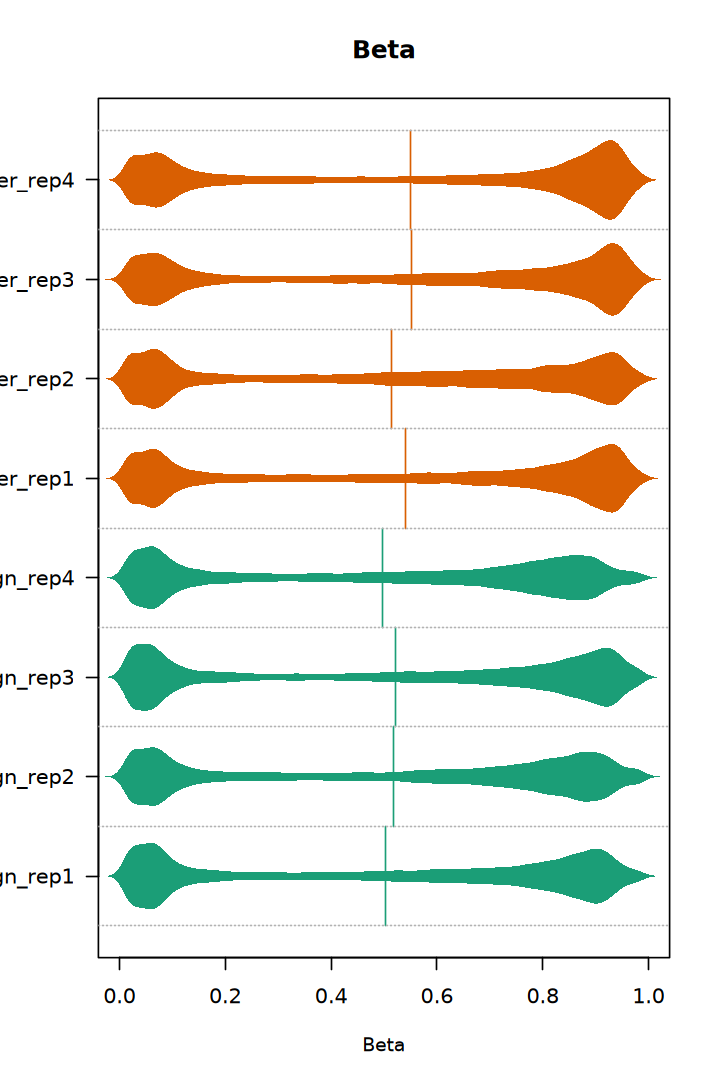

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 9)

densityBeanPlot(
    dat = rgSet, sampNames = sampleNames(rgSet), 
    sampGroups = rgSet$Sample_Group) |> 
    suppressWarnings()

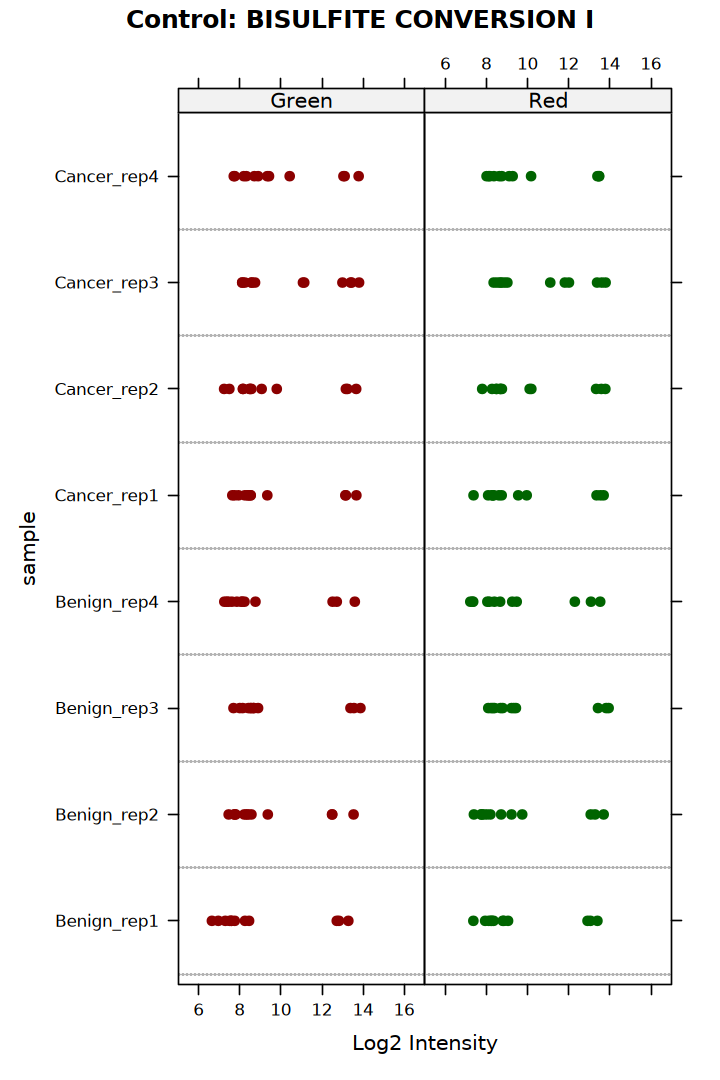

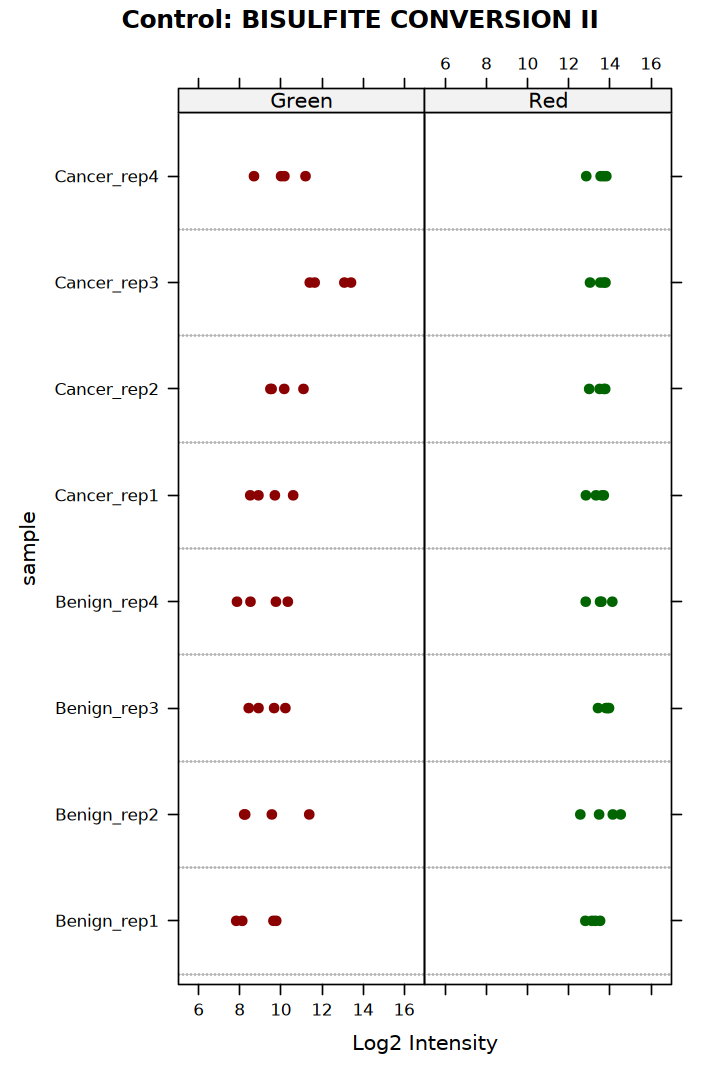

In [ ]:
options(repr.plot.width = 6, repr.plot.height = 9)

controlStripPlot(rgSet, sampNames = sampleNames(rgSet)) |> 
    suppressWarnings()

# 5. Normalization

> - `preprocessQuantile` function is more suited for datasets where you do not expect global differences between your samples.
> - `preprocessFunnorm` function is most appropriate for datasets with global methylation differences such as cancer/normal or vastly different tissue types.

In [ ]:
mSet_raw <- preprocessRaw(rgSet)

In [ ]:
mSet_1 <- preprocessQuantile(rgSet, sex = "M")

[preprocessQuantile] Mapping to genome.

[preprocessQuantile] Fixing outliers.

[preprocessQuantile] Quantile normalizing.



In [ ]:
mSet_2 <- preprocessFunnorm(rgSet, sex = "M")

[preprocessFunnorm] Background and dye bias correction with noob

[preprocessFunnorm] Mapping to genome

[preprocessFunnorm] Quantile extraction

[preprocessFunnorm] Normalization



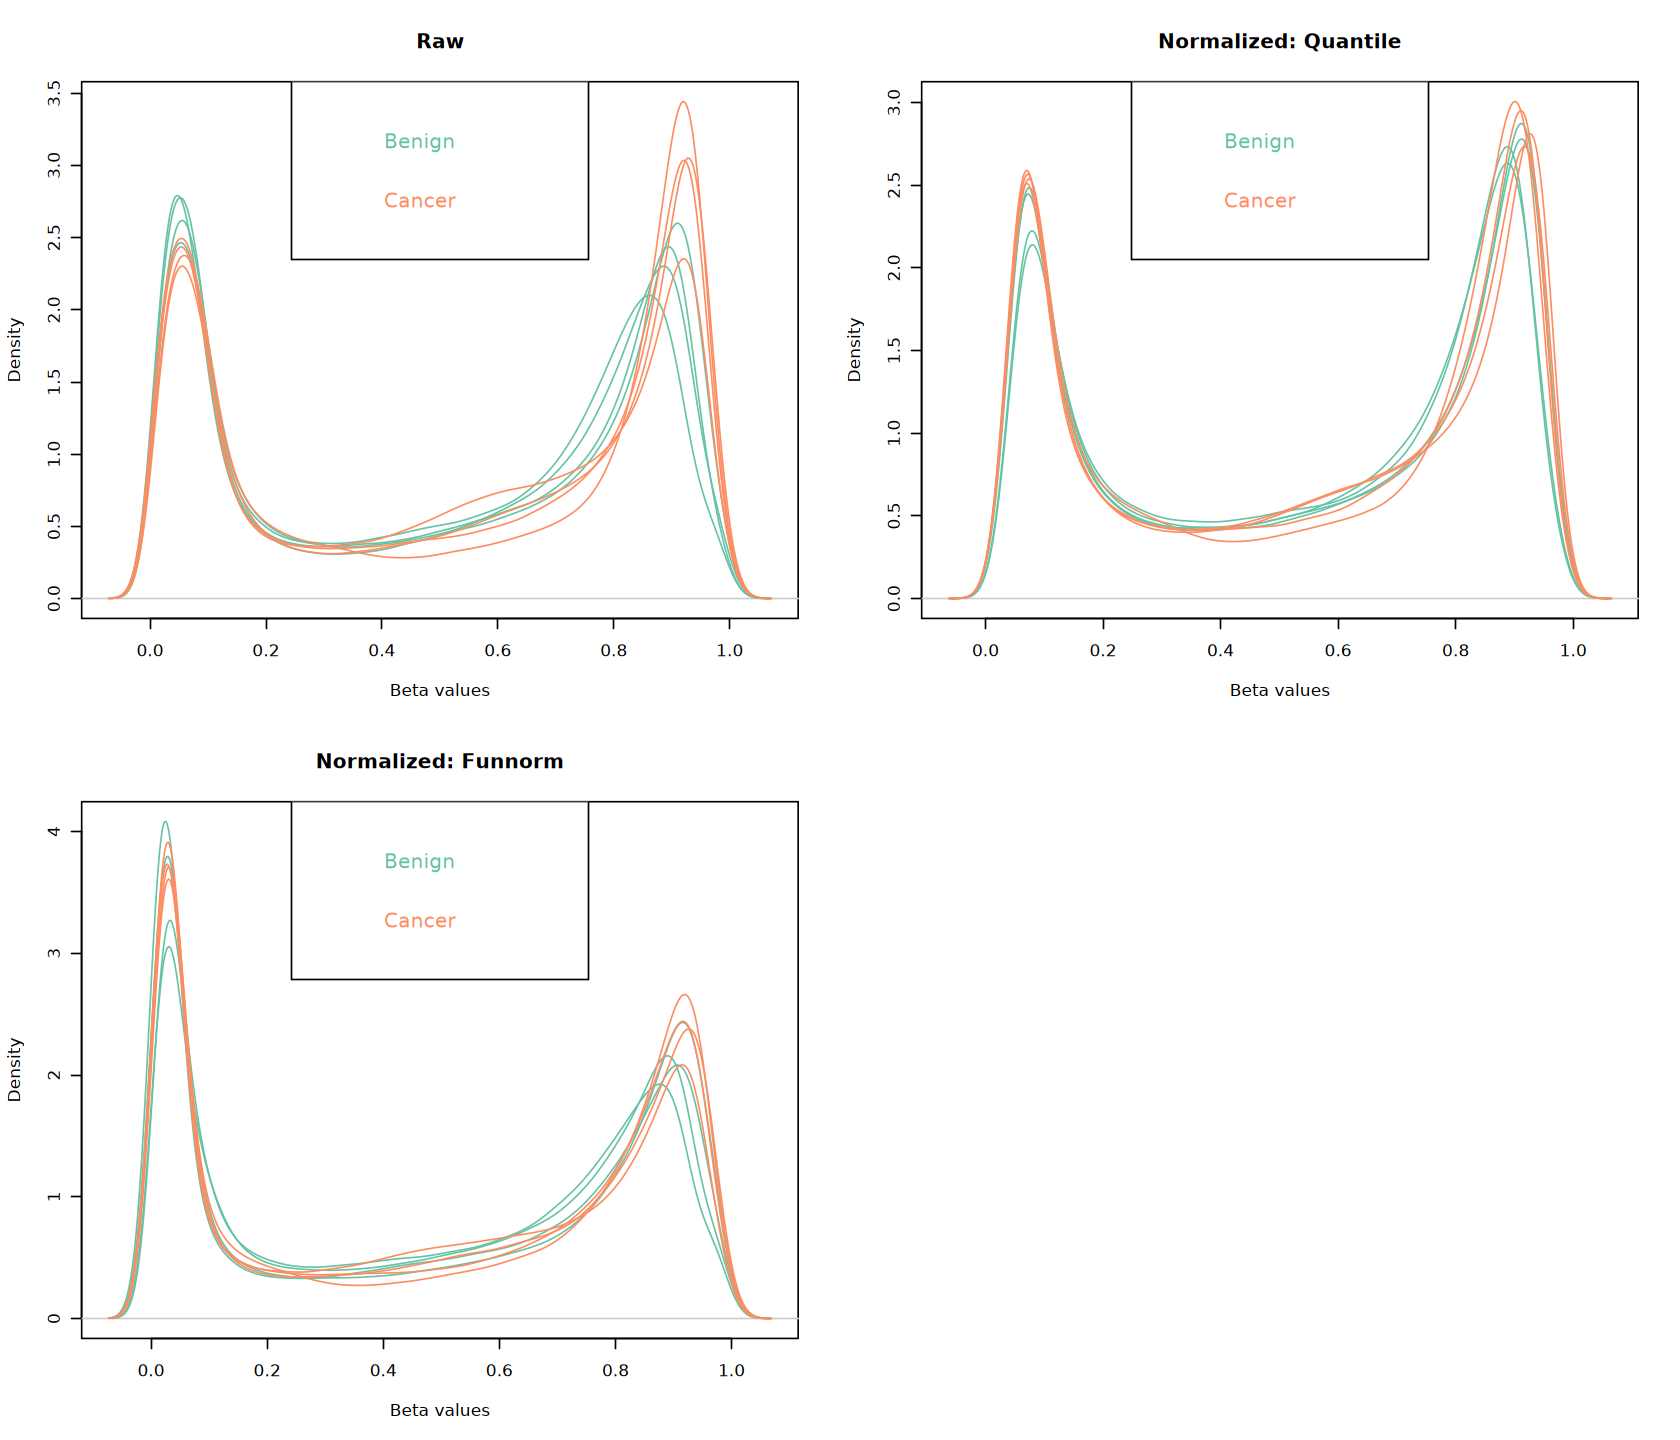

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 12)

par(mfrow = c(2, 2))
densityPlot(
    getBeta(mSet_raw), sampGroups = rgSet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main = "Raw", xlab = "Beta values")
legend("top", legend = levels(rgSet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

densityPlot(
    getBeta(mSet_1), sampGroups = rgSet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main = "Normalized: Quantile", xlab = "Beta values")
legend("top", legend = levels(rgSet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

densityPlot(
    getBeta(mSet_2), sampGroups = rgSet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main = "Normalized: Funnorm", xlab = "Beta values")
legend("top", legend = levels(rgSet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

In [ ]:
methySet <- mSet_2
methySet

class: GenomicRatioSet 
dim: 485512 8 
metadata(0):
assays(2): Beta CN
rownames(485512): cg13869341 cg14008030 ... cg08265308 cg14273923
rowData names(0):
colnames(8): Benign_rep1 Benign_rep2 ... Cancer_rep3 Cancer_rep4
colData names(8): Sample_Name Sample_Group ... Sample_Replicate
  filenames
Annotation
  array: IlluminaHumanMethylation450k
  annotation: ilmn12.hg19
Preprocessing
  Method: NA
  minfi version: NA
  Manifest version: NA

# 6. Data Exploration

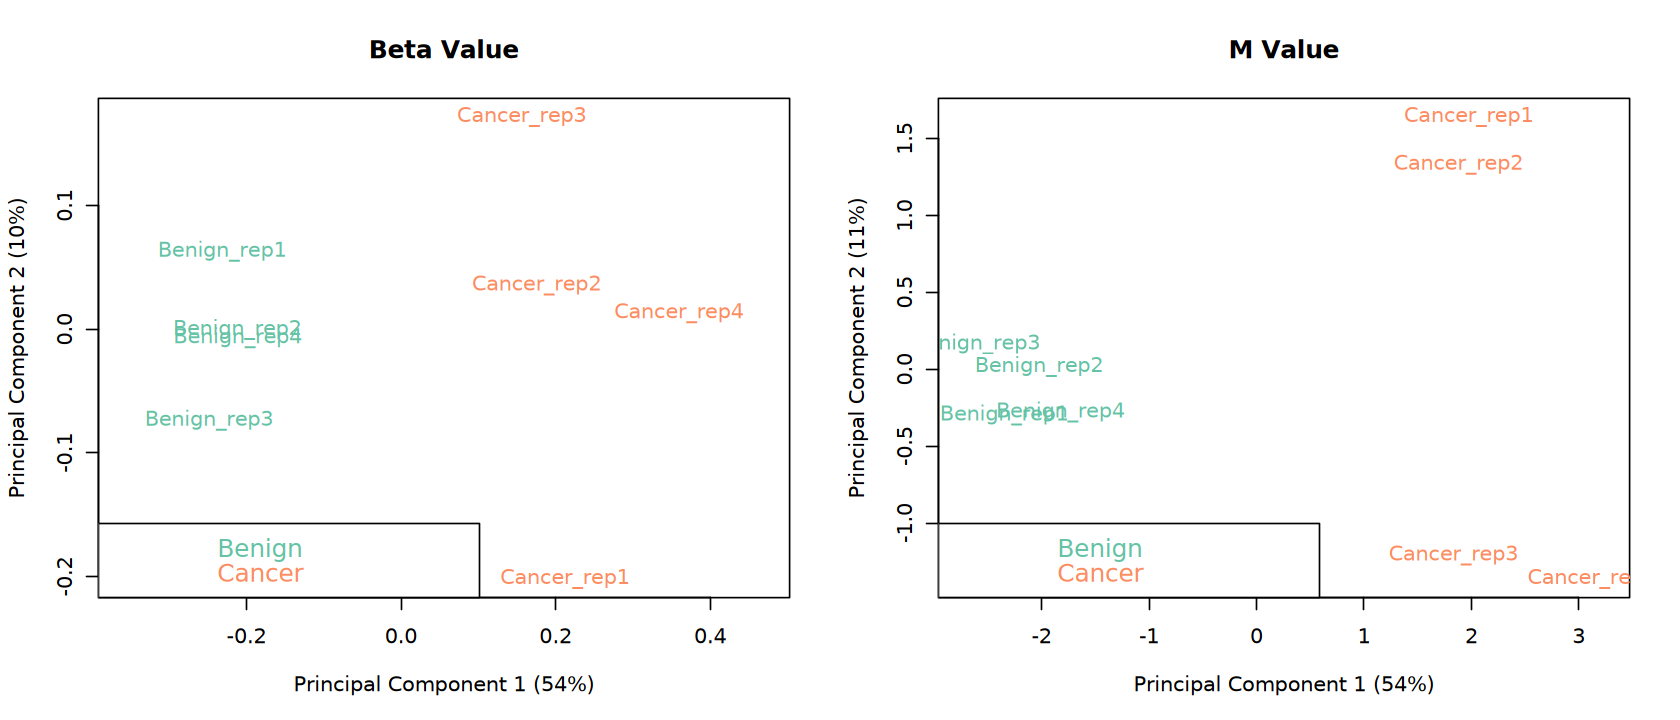

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

par(mfrow = c(1, 2))
plotMDS(
    getBeta(methySet), top = 1000, gene.selection = "common", 
    col = brewer.pal(8, "Set2")[methySet$Sample_Group], 
    main = "Beta Value")
legend("bottomleft", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

plotMDS(
    getM(methySet), top = 1000, gene.selection = "common", 
    col = brewer.pal(8, "Set2")[methySet$Sample_Group], 
    main = "M Value")
legend("bottomleft", legend = levels(methySet$Sample_Group), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

# 7. Filtering Probes

In [ ]:
# remove any probes that have failed in one or more samples
detP <- detP[match(featureNames(methySet), rownames(detP)), ] 
keep <- rowSums(detP < 0.01) == ncol(methySet)
methySet_filtered <- methySet[keep, ]

In [ ]:
# Calculate statistics
total_probes <- length(keep)
retained_probes <- sum(keep)
filtered_probes <- total_probes - retained_probes
filter_percentage <- (filtered_probes / total_probes) * 100

# Print summary
message("--- Probe Filtering Summary (Detection P-value > 0.01) ---")
message("Total probes starting:    ", total_probes)
message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
message("Probes retained:          ", retained_probes)
message("---------------------------------------------------------")

--- Probe Filtering Summary (Detection P-value > 0.01) ---

Total probes starting:    485512

Probes filtered out:      1618 (0.33%)

Probes retained:          483894

---------------------------------------------------------



In [ ]:
array_anno <- getAnnotation(IlluminaHumanMethylation450kanno.ilmn12.hg19)

In [ ]:
# remove probes on the sex chromosomes
keep <- !(featureNames(methySet_filtered) %in% 
    array_anno$Name[array_anno$chr %in% c("chrX", "chrY")])
methySet_filtered <- methySet_filtered[keep, ]

In [ ]:
# Calculate statistics
total_probes <- length(keep)
retained_probes <- sum(keep)
filtered_probes <- total_probes - retained_probes
filter_percentage <- (filtered_probes / total_probes) * 100

# Print summary
message("--- Probe Filtering Summary (Probes on sex chromosomes) ---")
message("Total probes starting:    ", total_probes)
message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
message("Probes retained:          ", retained_probes)
message("---------------------------------------------------------")

--- Probe Filtering Summary (Probes on sex chromosomes) ---

Total probes starting:    483894

Probes filtered out:      11563 (2.39%)

Probes retained:          472331

---------------------------------------------------------



In [ ]:
# remove probes with SNPs at CpG site
methySet_filtered <- dropLociWithSnps(
    methySet_filtered, snps = c("CpG", "SBE"), maf = 0)

In [ ]:
# Print summary
message("--- Probe Filtering Summary (Probes affected by SNP) ---")
message("Probes retained:          ", nrow(methySet_filtered))
message("---------------------------------------------------------")

--- Probe Filtering Summary (Probes affected by SNP) ---

Probes retained:          455448

---------------------------------------------------------



> - Chen, Y. an, Lemire, M., Choufani, S., Butcher, D. T., Grafodatskaya, D., Zanke, B. W., … Weksberg, R. (2013). Discovery of cross-reactive probes and polymorphic CpGs in the Illumina Infinium HumanMethylation450 microarray. Epigenetics, 8(2), 203–209. https://doi.org/10.4161/epi.23470.

In [ ]:
# # exclude cross reactive probes
# reactiveProbes <- read.csv(
#     file = "~/reference/Database/Others/48639-non-specific-probes-Illumina450k.xlsx", stringsAsFactors = FALSE)

# keep <- !(featureNames(methySet_filtered) %in% reactiveProbes$TargetID)

# methySet_filtered <- methySet_filtered[keep, ]

In [ ]:
# # Calculate statistics
# total_probes <- length(keep)
# retained_probes <- sum(keep)
# filtered_probes <- total_probes - retained_probes
# filter_percentage <- (filtered_probes / total_probes) * 100

# # Print summary
# message("--- Probe Filtering Summary (Cross reactive probes) ---")
# message("Total probes starting:    ", total_probes)
# message("Probes filtered out:      ", filtered_probes, " (", round(filter_percentage, 2), "%)")
# message("Probes retained:          ", retained_probes)
# message("---------------------------------------------------------")

# 8. Differentially Analysis

In [ ]:
# Extract beta values (proportion of methylation at each CpG site)
# Formula: M / (M + U + 100), where M = methylated intensity, U = unmethylated intensity
# Range: 0–1, where 0 = unmethylated and 1 = fully methylated
# More intuitive and suitable for visualization
bVals <- getBeta(methySet_filtered)

# Extract M values (log2 ratio of methylated vs unmethylated intensities)
# Formula: log2(M/U)
# Range: (-Inf, +Inf), approximately homoscedastic
# Statistically more appropriate for differential methylation analysis
mVals <- getM(methySet_filtered)

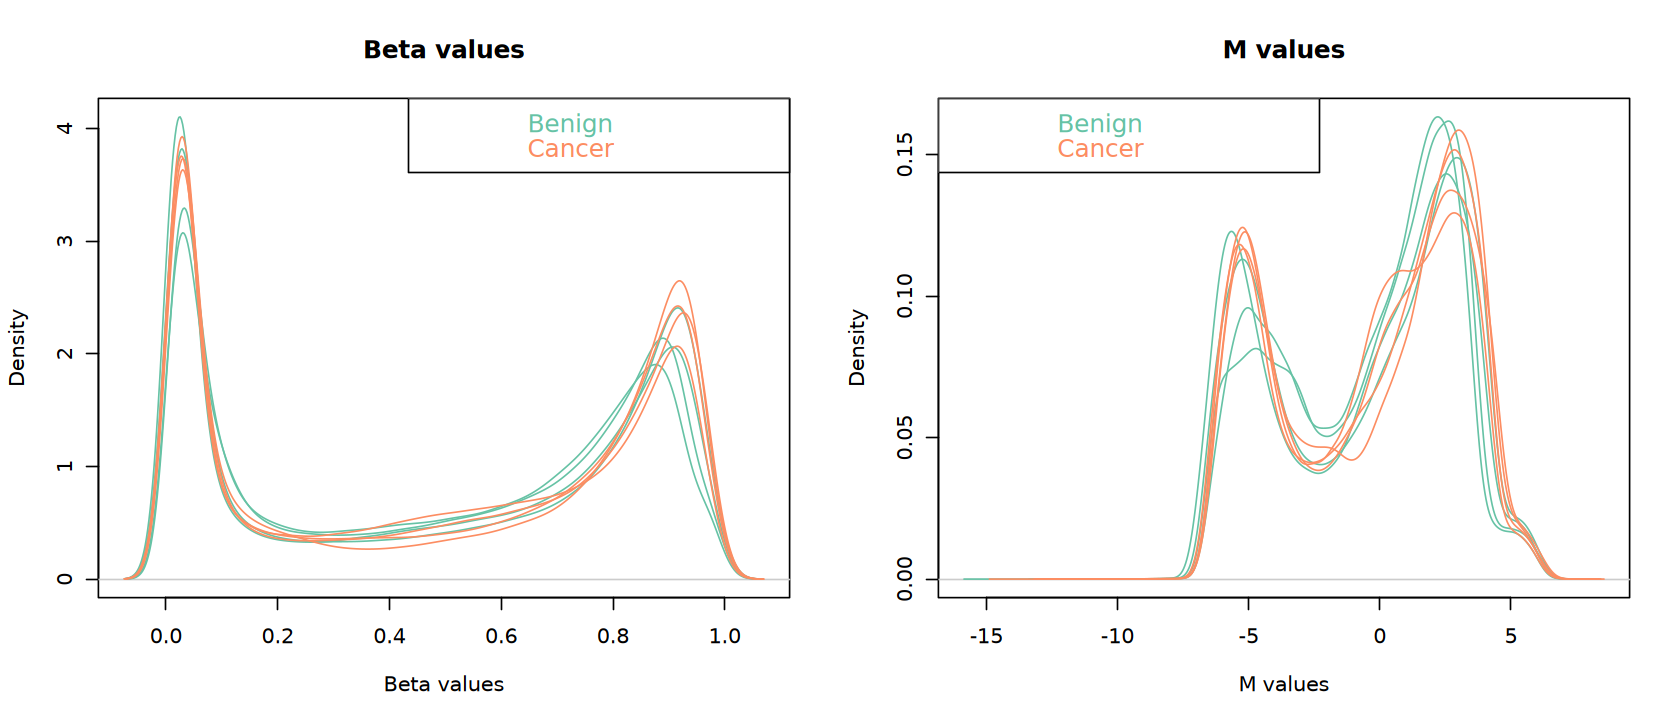

In [ ]:
options(repr.plot.width = 14, repr.plot.height = 6)

par(mfrow = c(1, 2))
densityPlot(
    bVals, sampGroups = methySet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main="Beta values", xlab="Beta values")
legend("topright", legend = levels(factor(methySet$Sample_Group)), 
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

densityPlot(
    mVals, sampGroups = methySet$Sample_Group, 
    pal = brewer.pal(8, "Set2"), legend = FALSE,
    main="M values", xlab="M values")
legend("topleft", legend = levels(factor(methySet$Sample_Group)),
    text.col = brewer.pal(8, "Set2"), 
    cex = 1.2, bg = "white", adj = c(0, 0.5))

In [ ]:
p_cutoff <- 0.01
logFC_cutoff <- 5

## 1). DMPs

In [ ]:
dmp_results <- dmpFinder(
    getM(methySet_filtered), pheno = methySet_filtered$Sample_Group, 
    type = "categorical", qCutoff = p_cutoff, shrinkVar = TRUE)

Warning message in contrasts.fit(fit, contrasts(pheno)):
"row names of contrasts don't match col names of coefficients"


In [ ]:
head(dmp_results)

,intercept,f,pval,qval
,<dbl>,<dbl>,<dbl>,<dbl>
cg19670286,5.974145,788.1326,2.284795e-10,1.554315e-05
cg24578679,5.762299,785.3135,2.323089e-10,1.554315e-05
cg27299406,6.554142,734.8949,3.159958e-10,1.554315e-05
cg23511432,6.367987,696.2269,4.059264e-10,1.554315e-05
cg14855334,5.687227,694.1197,4.116656e-10,1.554315e-05
cg20527270,6.182646,684.4576,4.392779e-10,1.554315e-05


## 2). DMPs (limma)

In [ ]:
design <- model.matrix( ~ Sample_Group, data = pData(methySet_filtered))

In [ ]:
design

,(Intercept),Sample_GroupCancer
Benign_rep1,1,0
Benign_rep2,1,0
Benign_rep3,1,0
Benign_rep4,1,0
Cancer_rep1,1,1
Cancer_rep2,1,1
Cancer_rep3,1,1
Cancer_rep4,1,1


In [ ]:
fit <- lmFit(mVals, design)
fit <- eBayes(fit)

In [ ]:
array_anno_sub <- array_anno[
    match(rownames(mVals), array_anno$Name), 
    c(1:4, 18:19, 24, 26)]

In [ ]:
dmps_result <- topTable(
    fit, coef = 2, number = Inf, genelist = array_anno_sub) |> 
    dplyr::rename(padj = adj.P.Val, pvalue = P.Value) |>
    mutate(
        result = case_when(
            pvalue < p_cutoff & logFC >  logFC_cutoff ~ "Up",
            pvalue < p_cutoff & logFC < -logFC_cutoff ~ "Down",
            TRUE ~ "NotSig") |> 
            factor(levels = c("Up", "Down", "NotSig")))

In [ ]:
head(dmps_result)
table(dmps_result$result)

,chr,pos,strand,Name,Islands_Name,Relation_to_Island,UCSC_RefGene_Name,UCSC_RefGene_Group,logFC,AveExpr,t,pvalue,padj,B,result
,<chr>,<int>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>
cg19670286,chr5,137610127,-,cg19670286,chr5:137610105-137610311,Island,GFRA3;GFRA3,1stExon;5'UTR,5.974145,-3.142866,28.07370,2.284795e-10,2.988889e-05,11.74959,Up
cg24578679,chr15,74658573,-,cg24578679,chr15:74658038-74658574,Island,CYP11A1;CYP11A1,Body;TSS200,5.762299,-3.314938,28.02344,2.323089e-10,2.988889e-05,11.74227,Up
cg27299406,chr2,43020013,+,cg27299406,chr2:43019665-43020509,Island,HAAO,TSS1500,6.554142,-2.816834,27.10895,3.159958e-10,2.988889e-05,11.60385,Up
cg23511432,chr5,137610255,+,cg23511432,chr5:137610105-137610311,Island,GFRA3,TSS200,6.367987,-2.792826,26.38611,4.059264e-10,2.988889e-05,11.48719,Up
cg14855334,chr15,74658553,-,cg14855334,chr15:74658038-74658574,Island,CYP11A1;CYP11A1,Body;TSS200,5.687227,-3.156372,26.34615,4.116656e-10,2.988889e-05,11.48054,Up
cg20527270,chr8,49468688,-,cg20527270,chr8:49468683-49468959,Island,,,6.182646,-1.801911,26.16214,4.392779e-10,2.988889e-05,11.44966,Up



    Up   Down NotSig 
   480      7 454961 

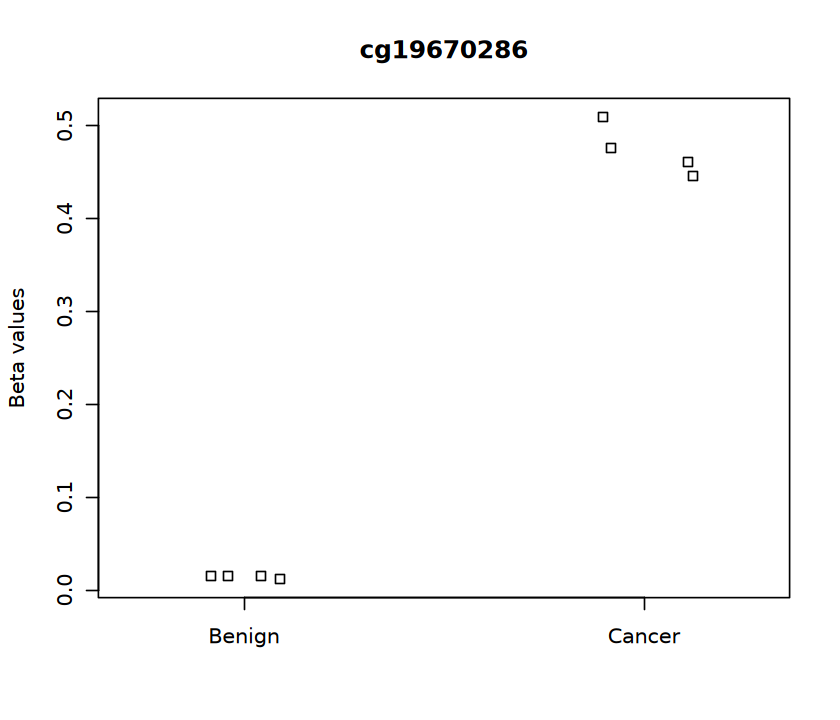

In [ ]:
options(repr.plot.width = 7, repr.plot.height = 6)
plotCpg(
    bVals, cpg = rownames(dmps_result)[1], 
    pheno = methySet_filtered$Sample_Group, 
    ylab = "Beta values")

## 3). DMRs

In [ ]:
design <- model.matrix( ~ Sample_Group, data = pData(methySet_filtered))

In [ ]:
dmr_result <- bumphunter(
    methySet_filtered, design, coef = 2, type = "M", 
    cutoff = 0.1, nullMethod = "permutation")

[bumphunterEngine] Using a single core (backend: doSEQ, version: 1.5.2).

[bumphunterEngine] Computing coefficients.

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 255019 bumps.



In [ ]:
head(dmr_result$table)

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL
,<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>
115321,chr6,29973557,29975708,3.832172,191.60861,157420,153654,153703,50,57
115692,chr6,30710898,30712680,3.688084,180.71614,157616,155754,155802,49,87
116167,chr6,31829644,31832486,2.873973,152.32059,157881,158376,158428,53,116
35486,chr12,115132761,115136308,1.829868,102.47261,48493,307525,307580,56,56
30446,chr12,4380025,4382425,2.174220,82.62035,41416,291149,291186,38,56
120347,chr6,133561765,133562776,2.605712,80.77706,163199,173803,173833,31,41


## 4). DMRs (DMRcate)

In [ ]:
design <- model.matrix( ~ Sample_Group, data = pData(methySet_filtered))

In [ ]:
cpg_anno <- cpg.annotate(
    object = mVals, datatype = "array", what = "M", arraytype = "450K",
    annotation = c(
        array = "IlluminaHumanMethylation450kanno", 
        annotation = "ilmn12.hg19"),
    analysis.type = "differential", design = design, coef = 2)

cpg_anno

Your contrast returned 32108 individually significant probes. We recommend the default setting of pcutoff in dmrcate().



CpGannotated object describing 455448 CpG sites, with independent
CpG threshold indexed at fdr=0.05 and 32108 significant CpG sites.

In [ ]:
dmrs <- dmrcate(cpg_anno, lambda = 1000, C = 2)

Fitting chr1...

Fitting chr2...

Fitting chr3...

Fitting chr4...

Fitting chr5...

Fitting chr6...

Fitting chr7...

Fitting chr8...

Fitting chr9...

Fitting chr10...

Fitting chr11...

Fitting chr12...

Fitting chr13...

Fitting chr14...

Fitting chr15...

Fitting chr16...

Fitting chr17...

Fitting chr18...

Fitting chr19...

Fitting chr20...

Fitting chr21...

Fitting chr22...

Demarcating regions...

Done!



In [ ]:
dmrs_result <- extractRanges(dmrs, genome = "hg19")

see ?DMRcatedata and browseVignettes('DMRcatedata') for documentation

loading from cache



In [ ]:
dmrs_result

GRanges object with 4524 ranges and 8 metadata columns:
         seqnames              ranges strand |   no.cpgs min_smoothed_fdr
            <Rle>           <IRanges>  <Rle> | <integer>        <numeric>
     [1]     chr6   30708859-30713442      * |        87                0
     [2]     chr6   29972884-29976071      * |        56                0
     [3]     chr3   25468324-25469991      * |        17                0
     [4]     chr5 112073348-112074043      * |        16                0
     [5]     chr2   43019484-43020682      * |        12                0
     ...      ...                 ...    ... .       ...              ...
  [4520]    chr17     1957529-1957607      * |         3      1.27384e-10
  [4521]     chr2 238768916-238769060      * |         2      1.29503e-10
  [4522]    chr19   54058440-54058516      * |         3      1.35616e-10
  [4523]    chr11     7985166-7985183      * |         2      1.36247e-10
  [4524]    chr17   35085060-35085134      * |         2

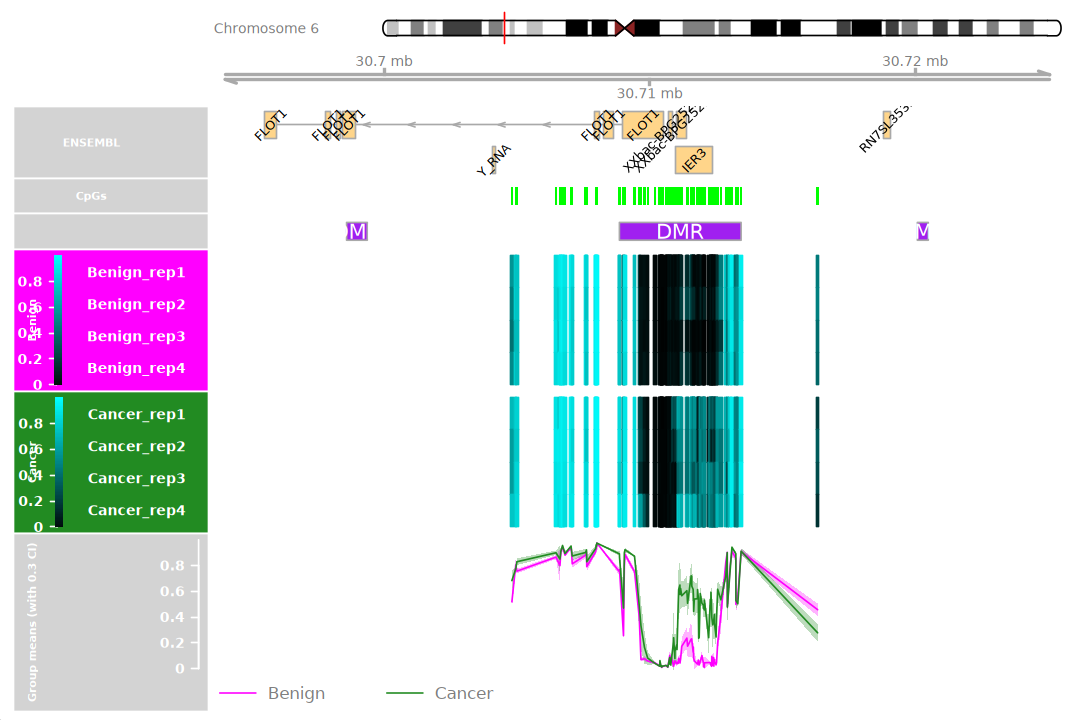

In [ ]:
options(repr.plot.width = 9, repr.plot.height = 6)

groups <- c(Benign = "magenta", Cancer = "forestgreen")
cols <- groups[as.character(methySet_filtered$Sample_Group)]

DMR.plot(
    ranges = dmrs_result, dmr = 1, CpGs = cpg_anno, what = "Beta",
    arraytype = "450K", phen.col = cols, genome = "hg19")

## 5). Blocks

In [ ]:
design <- model.matrix( ~ Sample_Group, data = pData(methySet_filtered))

In [ ]:
methySet_collapse <- cpgCollapse(methySet_filtered, what = "M")

[cpgCollapse] Creating annotation.


[cpgCollapseAnnotation] Clustering islands and clusters of probes.


[cpgCollapseAnnotation] Computing new annotation.


[cpgCollapseAnnotation] Defining blocks.


[cpgCollapse] Collapsing data



..........
.......


In [ ]:
block_result <- blockFinder(
    methySet_collapse$object, design, coef = 2, what = "M",
    cutoff = 0.1, nullMethod = "permutation")

[bumphunterEngine] Using a single core (backend: doSEQ, version: 1.5.2).

[bumphunterEngine] Computing coefficients.



[bumphunterEngine] Smoothing coefficients.

Loading required package: rngtools

[bumphunterEngine] Finding regions.

[bumphunterEngine] Found 5848 bumps.



In [ ]:
head(block_result$table)

,chr,start,end,value,area,cluster,indexStart,indexEnd,L,clusterL
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>,<int>,<dbl>,<int>
3256,chr1,157069426,159769263,-1.2131816,200.1750,33,14193,14407,165,1576
3252,chr1,151988500,153467760,-1.0851867,156.2669,33,13236,13413,144,1576
5546,chr16,85855366,87219610,-0.7184738,132.1992,680,175177,175452,184,1109
2020,chr10,78635553,81158982,0.4519604,127.4528,518,118317,118650,282,876
5078,chr11,130903135,133109552,-0.7956767,124.9212,554,135830,136014,157,1678
1651,chr7,157281250,158830070,0.5265433,111.6272,382,96680,97217,212,440


# 9. Visualization

In [ ]:
suppressPackageStartupMessages(library(Gviz))

In [ ]:
###############################################################################
# Customising visualisations of methylation data
################################################################################
# indicate which genome is being used
gen <- "hg19"
# the index of the DMR that we will plot 
dmrIndex <- 1
# extract chromosome number and location from DMR results 
chrom <- as.character(seqnames(results.ranges[dmrIndex]))
start <- as.numeric(start(results.ranges[dmrIndex]))
end <- as.numeric(end(results.ranges[dmrIndex]))
# add 25% extra space to plot
minbase <- start - (0.25*(end-start))
maxbase <- end + (0.25*(end-start))


# CpG islands
islandHMM <- read.csv(paste0(dataDirectory,
                             "/model-based-cpg-islands-hg19-chr17.txt"),
                      sep="\t", stringsAsFactors=FALSE, header=FALSE)
head(islandHMM)

islandData <- GRanges(seqnames=Rle(islandHMM[,1]), 
                      ranges=IRanges(start=islandHMM[,2], end=islandHMM[,3]),
                      strand=Rle(strand(rep("*",nrow(islandHMM)))))
islandData


# DNAseI hypersensitive sites
dnase <- read.csv(paste0(dataDirectory,"/wgEncodeRegDnaseClusteredV3chr17.bed"),
                  sep="\t",stringsAsFactors=FALSE,header=FALSE)
head(dnase)


dnaseData <- GRanges(seqnames=dnase[,1],
                     ranges=IRanges(start=dnase[,2], end=dnase[,3]),
                     strand=Rle(rep("*",nrow(dnase))),
                     data=dnase[,5])
dnaseData


iTrack <- IdeogramTrack(genome = gen, chromosome = chrom, name="")
gTrack <- GenomeAxisTrack(col="black", cex=1, name="", fontcolor="black")
rTrack <- UcscTrack(genome=gen, chromosome=chrom, track="NCBI RefSeq", 
                    from=minbase, to=maxbase, trackType="GeneRegionTrack", 
                    rstarts="exonStarts", rends="exonEnds", gene="name", 
                    symbol="name2", transcript="name", strand="strand", 
                    fill="darkblue",stacking="squish", name="RefSeq", 
                    showId=TRUE, geneSymbol=TRUE)

ann450kOrd <- ann450kSub[order(ann450kSub$chr,ann450kSub$pos),]
head(ann450kOrd)

bValsOrd <- bVals[match(ann450kOrd$Name,rownames(bVals)),]
head(bValsOrd)

# create genomic ranges object from methylation data
cpgData <- GRanges(seqnames=Rle(ann450kOrd$chr),
                   ranges=IRanges(start=ann450kOrd$pos, end=ann450kOrd$pos),
                   strand=Rle(rep("*",nrow(ann450kOrd))),
                   betas=bValsOrd)
# extract data on CpGs in DMR
cpgData <- subsetByOverlaps(cpgData, results.ranges[dmrIndex])

# methylation data track
methTrack <- DataTrack(range=cpgData, groups=targets$Sample_Group,genome = gen,
                       chromosome=chrom, ylim=c(-0.05,1.05), col=pal,
                       type=c("a","p"), name="DNA Meth.\n(beta value)",
                       background.panel="white", legend=TRUE, cex.title=0.8,
                       cex.axis=0.8, cex.legend=0.8)
# CpG island track
islandTrack <- AnnotationTrack(range=islandData, genome=gen, name="CpG Is.", 
                               chromosome=chrom,fill="darkgreen")

# DNaseI hypersensitive site data track
dnaseTrack <- DataTrack(range=dnaseData, genome=gen, name="DNAseI", 
                        type="gradient", chromosome=chrom)

# DMR position data track
dmrTrack <- AnnotationTrack(start=start, end=end, genome=gen, name="DMR", 
                            chromosome=chrom,fill="darkred")


tracks <- list(iTrack, gTrack, methTrack, dmrTrack, islandTrack, dnaseTrack,
               rTrack)
sizes <- c(2,2,5,2,2,2,3) # set up the relative sizes of the tracks
plotTracks(tracks, from=minbase, to=maxbase, showTitle=TRUE, add53=TRUE, 
           add35=TRUE, grid=TRUE, lty.grid=3, sizes = sizes, length(tracks))

---

# Reference

> 1. [Bioconductor workflow: methylationArrayAnalysis](https://www.bioconductor.org/packages/release/workflows/html/methylationArrayAnalysis.html)